In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime
import os
import concurrent.futures
from functools import partial

def load_file(file_path, separator):
    """Charge un fichier avec gestion des séparateurs et encodages"""
    if not os.path.exists(file_path):
        print(f"Fichier introuvable: {file_path}")
        return pd.DataFrame()
        
    encodings = ['utf-8', 'latin1', 'ISO-8859-1']
    
    for encoding in encodings:
        try:
            df = pd.read_csv(file_path, sep=separator, encoding=encoding, 
                            low_memory=False, on_bad_lines='skip')
            df.columns = df.columns.str.strip()
            print(f"Fichier chargé avec succès: {file_path}")
            
            # Optimisation: convertir directement les colonnes lors du chargement
            df = convert_columns(df)
            return df
        except Exception as e:
            print(f"Erreur lors du chargement avec l'encoding {encoding}: {str(e)}")
            continue
            
    print(f"Impossible de charger le fichier {file_path} avec les encodages testés")
    return pd.DataFrame()

def convert_columns(df):
    """Convertit les colonnes numériques et dates en une seule passe"""
    # Colonnes numériques potentielles
    numeric_cols = ['MONTANT', 'NOMBRE', 'MONTANT_TOTAL', 'SOLDE', 'MVTDEB', 'MVTCRED', 'NOMBRE_OPE', 'NOMBRE_OPERATION', 'CONNECTIONCOUNT']
    
    # Colonnes de dates potentielles
    date_cols = ['DATE_OF_BIRTH', 'CUSTOMER_SINCE', 'DT_CONFIRMATION', 
                'DATE_OCTROI', 'DT_FIN_DOSS_REEL', 'DATE_DEM_ABON', 
                'DATE_RES_ABON', 'DATE_VAL_ABON', 'CREATEDATE', 'LASTLOGINDATE', 'DT_CREATE', 'DT_ENR']
    
    date_formats = ['%Y%m%d', '%d/%m/%Y', '%m/%y', '%d/%m/%y', '%Y-%m-%d']
    
    # Correction encodage pour colonnes textuelles
    for col in df.columns:
        if df[col].dtype == 'object':
            # Convertir les colonnes numériques
            if col in numeric_cols:
                df[col] = pd.to_numeric(df[col].astype(str)
                                        .str.replace(',', '.')
                                        .str.replace(' ', ''), 
                                      errors='coerce')
                                      
            # Convertir les colonnes de date
            elif col in date_cols:
                for date_format in date_formats:
                    try:
                        df[col] = pd.to_datetime(df[col], format=date_format, errors='coerce')
                        break
                    except:
                        continue
                        
            # Corriger l'encodage des chaînes de caractères restantes
            else:
                try:
                    df[col] = df[col].apply(lambda x: x.encode('latin1', errors='ignore')
                                           .decode('utf-8', errors='ignore') 
                                           if isinstance(x, str) else x)
                except:
                    pass
    
    return df

def preserve_identifiers_format(df, id_columns):
    """Préserve le format des identifiants en assurant qu'ils ont 7 chiffres avec des zéros au début si nécessaire"""
    for col in id_columns:
        if col in df.columns:
            # Conversion des identifiants en chaînes de caractères
            df[col] = df[col].astype(str)
            
            # Supprimer les espaces et NaN
            df[col] = df[col].str.strip()
            df[col] = df[col].replace('nan', '')
            
            # Appliquer le padding pour assurer 7 chiffres
            df[col] = df[col].apply(lambda x: x.zfill(7) if x and x.isdigit() else x)
    
    return df

def load_all_files_parallel(data_files):
    """Charge tous les fichiers en parallèle"""
    os.makedirs('data', exist_ok=True)
    
    df_dict = {}
    missing_files = []
    
    # Fonction partielle pour le multiprocessing
    load_file_wrapper = lambda args: (args[0], load_file(args[1], args[2]))
    
    # Charger les fichiers en parallèle
    with concurrent.futures.ThreadPoolExecutor(max_workers=min(len(data_files), os.cpu_count() or 4)) as executor:
        results = executor.map(load_file_wrapper, data_files)
        
    for name, df in results:
        if not df.empty:
            # Préserver le format des identifiants
            id_columns = ['RADICAL', 'CONTRAT']
            df = preserve_identifiers_format(df, id_columns)
            df_dict[name] = df
        else:
            missing_files.append(name)
    
    return df_dict, missing_files

def main():
    data_path = "/home/kaoutar/Desktop/data"
    
    data_files = [
        ('transferts', f'{data_path}/ACT_CD_TRANSFERTS_COMPTE_MDMV20032025.txt', '|'),
        ('connexions', f'{data_path}/ACT_CD_STAT_CONNEXION_MDM28032025.txt', '|'),
        ('perimetre', f'{data_path}/Périmétre_projet.txt', '|'),
        ('soldes', f'{data_path}/ACT_CD_SOLDE_CLIENT_MDM28032025.txt', '|'),
        ('equipements', f'{data_path}/ACT_EQUI_MDM28032025.txt', '|'),
        ('transactions', f'{data_path}/ACT_CD_TRANSA_MDM20032025.txt', '|'),
        ('produits', f'{data_path}/ACT_CD_PRODUIT_MDM20032025.txt', '|'),
        ('operations', f'{data_path}/ACT_CD_OPERATIONS_AGENCE_MDM20032025.txt', ';'),
        ('vignettes', f'{data_path}/ACT_CD_PAI_VIGNETTE_MDM20032025.txt', '|'),
        ('cheques', f'{data_path}/ACT_CD_GETCHQ_MDM28032025.txt', '|'),
        ('credits', f'{data_path}/ACT_CD_CREDIT_MDM28032025.txt', '|')
    ]
    
    
    
    try:
        # Chargement parallèle des fichiers
        print("Chargement des fichiers en parallèle...")
        df_dict, missing_files = load_all_files_parallel(data_files)
        
        # Vérifier les fichiers critiques
        if missing_files:
            print("\nFichiers non chargés:")
            for file_path in missing_files:
                print(f"- {file_path}")
            
            critical_files = ['perimetre', 'connexions', 'transactions', 'cheques', 'vignettes', 'equipements']
            missing_critical = [file for file in critical_files if file not in df_dict]
            if missing_critical:
                print(f"\nImpossible de continuer: fichiers nécessaires manquants: {', '.join(missing_critical)}")
                return
        
        # IMPORTANT: S'assurer que le fichier de périmètre est présent
        if 'perimetre' not in df_dict:
            print("Fichier périmètre manquant - impossible de continuer")
            return
        
        # Afficher un aperçu du fichier équipements pour debug
        if 'equipements' in df_dict:
            print("\nAperçu du fichier équipements:")
            print(f"Colonnes disponibles: {df_dict['equipements'].columns.tolist()}")
            
            # Afficher la distribution des valeurs de ETAT et LIBELLE
            if 'ETAT' in df_dict['equipements'].columns and 'LIBELLE' in df_dict['equipements'].columns:
                print("\nDistribution des valeurs dans ETAT:")
                etat_status = df_dict['equipements']['ETAT'].value_counts()
                print(etat_status)
                
                print("\nDistribution des valeurs dans LIBELLE:")
                # Afficher quelques valeurs brutes pour vérifier les espaces
                print("Exemples de valeurs dans LIBELLE (avec représentation des caractères invisibles):")
                libelle_samples = df_dict['equipements']['LIBELLE'].head(10).apply(lambda x: repr(x) if isinstance(x, str) else x)
                print(libelle_samples)
                
                libelle_status = df_dict['equipements']['LIBELLE'].value_counts().head(10)  # Afficher les 10 plus fréquents
                print(libelle_status)
                
                # Nombre total d'équipements validés
                # MODIFICATION: Utiliser la méthode str.strip() et str.upper() pour normaliser les valeurs
                validations = df_dict['equipements'][
                    (df_dict['equipements']['ETAT'].astype(str).str.strip() == '2') & 
                    (df_dict['equipements']['LIBELLE'].astype(str).str.strip().str.upper() == 'VALIDE')
                ].shape[0]
                print(f"Nombre total d'équipements validés (ETAT=2, LIBELLE=VALIDE): {validations}")
        
        # Vérifier le format des identifiants
        print("\nVérification du format des identifiants...")
        for name, df in df_dict.items():
            if 'RADICAL' in df.columns:
                sample_radical = df['RADICAL'].iloc[0] if not df.empty else "N/A"
                print(f"- {name}: Format RADICAL exemple: {sample_radical}")
                
            if 'CONTRAT' in df.columns:
                sample_contrat = df['CONTRAT'].iloc[0] if not df.empty else "N/A"
                print(f"- {name}: Format CONTRAT exemple: {sample_contrat}")
        
        # MODIFICATION: Extraire clairement tous les identifiants du périmètre
        print("\nIdentification des clients du périmètre...")
        contrat_col = 'CONTRAT'
        
        # Récupérer tous les identifiants du fichier périmètre
        perimetre_df = df_dict['perimetre']
        
        # Assurer que les identifiants sont du bon format (7 chiffres)
        perimetre_df = preserve_identifiers_format(perimetre_df, ['RADICAL', contrat_col])
        
        # Collecter tous les identifiants du périmètre (RADICAL et CONTRAT)
        perimetre_identifiers = set(perimetre_df['RADICAL'].dropna().unique())
        
        # Ajouter les contrats associés s'ils existent
        if contrat_col in perimetre_df.columns:
            perimetre_identifiers.update(perimetre_df[contrat_col].dropna().unique())
        
        print(f"Nombre de clients dans le périmètre: {len(perimetre_identifiers)}")
        
        # Optimisation: créer une table de correspondance unique pour les identifiants
        # Dictionnaire pour stocker les correspondances RADICAL-CONTRAT
        identifier_map = {}
        
        # Construire la table de correspondance en une seule passe
        for name, df in df_dict.items():
            if 'RADICAL' in df.columns and contrat_col in df.columns:
                print(f"Extraction des relations RADICAL-CONTRAT depuis {name}...")
                
                # Optimisation: utiliser des opérations vectorisées
                matched_rows = df[df['RADICAL'].notna() & df[contrat_col].notna()]
                
                for _, row in matched_rows.iterrows():
                    radical = row['RADICAL']
                    contrat = row[contrat_col]
                    
                    # Enregistrer uniquement les correspondances pour les clients du périmètre
                    if radical in perimetre_identifiers or contrat in perimetre_identifiers:
                        # Stocker les correspondances dans les deux sens
                        identifier_map[radical] = contrat
                        identifier_map[contrat] = radical
        
        # 1. Clients avec transactions
        print("\nIdentification des clients avec transactions...")
        transaction_clients = set()
        if 'transactions' in df_dict:
            transactions_df = df_dict['transactions']
            if 'RADICAL' in transactions_df.columns and 'NOMBRE_OPE' in transactions_df.columns:
                # Filtrer les clients avec au moins une opération
                transaction_mask = (transactions_df['RADICAL'].notna() & 
                                   (transactions_df['NOMBRE_OPE'] >= 1))
                
                transaction_identifiers = transactions_df.loc[transaction_mask, 'RADICAL']
                
                # Filtrer pour ne garder que les clients du périmètre
                transaction_clients.update(id for id in transaction_identifiers if id in perimetre_identifiers)
                
                # Ajouter les identifiants équivalents du périmètre
                for identifier in list(transaction_clients):
                    if identifier in identifier_map and identifier_map[identifier] in perimetre_identifiers:
                        transaction_clients.add(identifier_map[identifier])
        
        print(f"Nombre de clients avec transactions: {len(transaction_clients)}")
        
        # 2. Clients GETCHQ
        print("\nIdentification des clients GETCHQ...")
        getchq_clients = set()
        if 'cheques' in df_dict:
            cheques_df = df_dict['cheques']
            
            # Traiter les identifiants RADICAL
            if 'RADICAL' in cheques_df.columns:
                getchq_radical = cheques_df[cheques_df['RADICAL'].notna()]['RADICAL']
                getchq_clients.update(id for id in getchq_radical if id in perimetre_identifiers)
            
            # Traiter les identifiants CONTRAT
            if contrat_col in cheques_df.columns:
                getchq_contrat = cheques_df[cheques_df[contrat_col].notna()][contrat_col]
                getchq_clients.update(id for id in getchq_contrat if id in perimetre_identifiers)
            
            # Ajouter les identifiants équivalents du périmètre
            for identifier in list(getchq_clients):
                if identifier in identifier_map and identifier_map[identifier] in perimetre_identifiers:
                    getchq_clients.add(identifier_map[identifier])
        
        print(f"Nombre de clients GETCHQ: {len(getchq_clients)}")
        
        # 3. Clients vignettes
        print("\nIdentification des clients vignette...")
        vignette_clients = set()
        if 'vignettes' in df_dict:
            vignettes_df = df_dict['vignettes']
            if 'RADICAL' in vignettes_df.columns:
                vignette_radical = vignettes_df[vignettes_df['RADICAL'].notna()]['RADICAL']
                vignette_clients.update(id for id in vignette_radical if id in perimetre_identifiers)
                
                # Ajouter les identifiants équivalents du périmètre
                for identifier in list(vignette_clients):
                    if identifier in identifier_map and identifier_map[identifier] in perimetre_identifiers:
                        vignette_clients.add(identifier_map[identifier])
        
        print(f"Nombre de clients vignette: {len(vignette_clients)}")
        
        # 4. Clients avec abonnements validés
        print("\nIdentification des clients avec abonnements validés...")
        abonnement_clients = set()
        if 'equipements' in df_dict:
            equipements_df = df_dict['equipements']
            if 'RADICAL' in equipements_df.columns and 'ETAT' in equipements_df.columns and 'LIBELLE' in equipements_df.columns:
                # Nettoyer et normaliser les valeurs ETAT et LIBELLE
                equipements_df['ETAT_CLEAN'] = equipements_df['ETAT'].astype(str).str.strip()
                equipements_df['LIBELLE_CLEAN'] = equipements_df['LIBELLE'].astype(str).str.strip().str.upper()
                
                # Debug: afficher les valeurs distinctes après nettoyage
                print("\nValeurs distinctes dans ETAT après nettoyage:")
                print(equipements_df['ETAT_CLEAN'].value_counts())
                
                print("\nValeurs distinctes dans LIBELLE après nettoyage:")
                print(equipements_df['LIBELLE_CLEAN'].value_counts().head(10))
                
                # Filtrer pour les abonnements validés avec valeurs normalisées
                abonnement_mask = (equipements_df['RADICAL'].notna() & 
                                 (equipements_df['ETAT_CLEAN'] == '2') & 
                                 (equipements_df['LIBELLE_CLEAN'] == 'VALIDE'))
                
                # Debug: afficher le nombre de lignes qui correspondent à ces critères
                matching_rows = equipements_df[abonnement_mask]
                print(f"\nNombre de lignes avec ETAT=2 et LIBELLE=VALIDE: {len(matching_rows)}")
                
                if not matching_rows.empty:
                    print("Exemples de lignes correspondantes:")
                    print(matching_rows[['RADICAL', 'ETAT', 'LIBELLE', 'ETAT_CLEAN', 'LIBELLE_CLEAN']].head())
                
                abonnement_identifiers = equipements_df.loc[abonnement_mask, 'RADICAL']
                
                # Filtrer pour ne garder que les clients du périmètre
                abonnement_clients.update(id for id in abonnement_identifiers if id in perimetre_identifiers)
                
                # Debug: afficher quelques identifiants
                if abonnement_clients:
                    print("\nExemples d'identifiants de clients avec abonnements validés:")
                    print(list(abonnement_clients)[:5])
                
                # Ajouter les identifiants équivalents du périmètre
                for identifier in list(abonnement_clients):
                    if identifier in identifier_map and identifier_map[identifier] in perimetre_identifiers:
                        abonnement_clients.add(identifier_map[identifier])
        
        print(f"Nombre de clients avec abonnements validés: {len(abonnement_clients)}")
        
        # Si aucun abonnement trouvé, essayer une approche plus permissive
        if len(abonnement_clients) == 0 and 'equipements' in df_dict:
            print("\nAucun abonnement validé trouvé avec les critères exacts. Essai avec critères plus permissifs...")
            
            # Si le problème est qu'il n'y a pas de ligne exactement "VALIDE", prenons toutes les lignes avec ETAT=2
            equipements_df = df_dict['equipements']
            if 'RADICAL' in equipements_df.columns and 'ETAT' in equipements_df.columns:
                permissive_mask = (equipements_df['RADICAL'].notna() & 
                                 (equipements_df['ETAT'].astype(str).str.strip() == '2'))
                
                permissive_ids = equipements_df.loc[permissive_mask, 'RADICAL']
                
                # Filtrer pour ne garder que les clients du périmètre
                abonnement_clients.update(id for id in permissive_ids if id in perimetre_identifiers)
                
                # Ajouter les identifiants équivalents du périmètre
                for identifier in list(abonnement_clients):
                    if identifier in identifier_map and identifier_map[identifier] in perimetre_identifiers:
                        abonnement_clients.add(identifier_map[identifier])
                
                print(f"Nombre de clients avec abonnements (critère permissif ETAT=2): {len(abonnement_clients)}")
        
        # MODIFICATION: Traitement des clients connectés séparément (information uniquement, pas utilisée pour l'appétence)
        print("\nIdentification des clients connectés (information uniquement)...")
        connected_clients = set()
        if 'connexions' in df_dict:
            connexions_df = df_dict['connexions']
            if contrat_col in connexions_df.columns:
                # Un client est considéré comme connecté si:
                # 1. Il a une valeur 'Connecte Reussi' dans CONNECTION, OU
                # 2. Il a un nombre de connexions CONNECTIONCOUNT > 0
                
                # Condition 1: CONNECTION contient 'Connecte Reussi'
                if 'CONNECTION' in connexions_df.columns:
                    connected_mask1 = connexions_df[contrat_col].notna() & connexions_df['CONNECTION'].str.contains('Connecte Reussi', case=False, na=False)
                    connected_ids1 = set(connexions_df.loc[connected_mask1, contrat_col])
                    print(f"Nombre de clients avec 'Connecte Reussi': {len(connected_ids1)}")
                    connected_clients.update(id for id in connected_ids1 if id in perimetre_identifiers)
                
                # Condition 2: CONNECTIONCOUNT > 0
                if 'CONNECTIONCOUNT' in connexions_df.columns:
                    connexions_df['CONNECTIONCOUNT'] = pd.to_numeric(connexions_df['CONNECTIONCOUNT'], errors='coerce')
                    connected_mask2 = connexions_df[contrat_col].notna() & (connexions_df['CONNECTIONCOUNT'] > 0)
                    connected_ids2 = set(connexions_df.loc[connected_mask2, contrat_col])
                    print(f"Nombre de clients avec CONNECTIONCOUNT > 0: {len(connected_ids2)}")
                    connected_clients.update(id for id in connected_ids2 if id in perimetre_identifiers)
                
                # Ou utiliser les deux colonnes CREATEDATE et LASTLOGINDATE si elles existent et sont différentes
                if 'CREATEDATE' in connexions_df.columns and 'LASTLOGINDATE' in connexions_df.columns:
                    # Un client qui s'est connecté aura des dates différentes
                    date_mask = (connexions_df[contrat_col].notna() & 
                                  connexions_df['CREATEDATE'].notna() & 
                                  connexions_df['LASTLOGINDATE'].notna() & 
                                  (connexions_df['CREATEDATE'] != connexions_df['LASTLOGINDATE']))
                    connected_ids3 = set(connexions_df.loc[date_mask, contrat_col])
                    print(f"Nombre de clients avec dates différentes: {len(connected_ids3)}")
                    connected_clients.update(id for id in connected_ids3 if id in perimetre_identifiers)
                
                # Ajouter les identifiants équivalents du périmètre
                for identifier in list(connected_clients):
                    if identifier in identifier_map and identifier_map[identifier] in perimetre_identifiers:
                        connected_clients.add(identifier_map[identifier])
        
        print(f"Nombre total de clients connectés: {len(connected_clients)}")
        
        # Construction du dataset unifié
        print("\nConstruction du dataset unifié...")
        
        # Préparation du DataFrame final
        unified_data = {
            'IDENTIFIER': list(perimetre_identifiers),  # Tous les clients du périmètre
            'connected': [id in connected_clients for id in perimetre_identifiers],  # Info connexion (pas utilisée pour appétence)
            'has_transaction': [id in transaction_clients for id in perimetre_identifiers],
            'used_getchq': [id in getchq_clients for id in perimetre_identifiers],
            'paid_vignette': [id in vignette_clients for id in perimetre_identifiers],
            'validated_subscription': [id in abonnement_clients for id in perimetre_identifiers],
        }
        
        # MODIFICATION: Calculer l'appétence basée sur la nouvelle définition
# Un client est appétent s'il:
# 1. Est dans le périmètre (déjà filtré dans unified_data)
# 2. A un abonnement validé ET
# 3. A réalisé au moins une des actions suivantes:
#    - Au moins une transaction
#    - Utilisé le service GETCHQ
#    - Payé une vignette en ligne
        unified_data['has_any_action'] = [(t or g or v) for t, g, v in 
                               zip(unified_data['has_transaction'],
                                   unified_data['used_getchq'],
                                   unified_data['paid_vignette'])]

        unified_data['appetent'] = [(s and a) for s, a in 
                          zip(unified_data['validated_subscription'],
                              unified_data['has_any_action'])]
        
        # Créer le DataFrame unifié
        unified_df = pd.DataFrame(unified_data)
        
        # Joindre les données de périmètre
        perimetre_df = df_dict['perimetre'].copy()
        
        # Créer une version "longue" de perimetre avec RADICAL et CONTRAT séparément
        radical_perim = perimetre_df[['RADICAL', 'GENRE', 'STATUT_MARITAL', 'DATE_OF_BIRTH', 
                                     'CTRY_OF_BIRTH', 'RESIDENCE', 'CR_PROFIL', 'CUSTOMER_SINCE']]
        radical_perim.rename(columns={'RADICAL': 'IDENTIFIER'}, inplace=True)
        
        if contrat_col in perimetre_df.columns:
            contrat_perim = perimetre_df[[contrat_col, 'GENRE', 'STATUT_MARITAL', 'DATE_OF_BIRTH', 
                                        'CTRY_OF_BIRTH', 'RESIDENCE', 'CR_PROFIL', 'CUSTOMER_SINCE']]
            contrat_perim.rename(columns={contrat_col: 'IDENTIFIER'}, inplace=True)
            
            # Concaténer les deux versions
            perim_long = pd.concat([radical_perim, contrat_perim], ignore_index=True)
        else:
            perim_long = radical_perim
        
        # Supprimer les doublons
        perim_long.drop_duplicates(subset=['IDENTIFIER'], inplace=True)
        
        # Jointure gauche pour conserver tous les clients du périmètre
        unified_df = pd.merge(unified_df, perim_long, on='IDENTIFIER', how='left')
        


        output_file = f'{data_path}/dataset_unifie_perimetre_appetent222.csv'  # ou un autre chemin de votre choix
        unified_df.to_csv(output_file, index=False)
        print(f"\nDataset unifié sauvegardé dans {output_file}")
        
        # Afficher les statistiques
        appetent_count = unified_df['appetent'].sum()
        total_count = len(unified_df)
        print(f"\nNombre total de clients du périmètre: {total_count}")
        print(f"Nombre de clients appétents: {appetent_count} ({appetent_count/total_count*100:.2f}%)")
        print(f"Nombre de clients non appétents: {total_count - appetent_count} ({(total_count - appetent_count)/total_count*100:.2f}%)")
        
        # Afficher la distribution des profils si disponible
        if 'CR_PROFIL' in unified_df.columns:
            print("\nDistribution des profils:")
            print(unified_df['CR_PROFIL'].value_counts())
        
        # Afficher statistiques des facteurs d'appétence
        print("\nStatistiques des facteurs d'appétence:")
        print(f"- Clients connectés: {unified_df['connected'].sum()} ({unified_df['connected'].sum()/total_count*100:.2f}%) [Info uniquement]")
        print(f"- Clients avec transactions: {unified_df['has_transaction'].sum()} ({unified_df['has_transaction'].sum()/total_count*100:.2f}%)")
        print(f"- Clients GETCHQ: {unified_df['used_getchq'].sum()} ({unified_df['used_getchq'].sum()/total_count*100:.2f}%)")
        print(f"- Clients vignette: {unified_df['paid_vignette'].sum()} ({unified_df['paid_vignette'].sum()/total_count*100:.2f}%)")
        print(f"- Clients avec abonnements validés: {unified_df['validated_subscription'].sum()} ({unified_df['validated_subscription'].sum()/total_count*100:.2f}%)")
        
        
        # Analyse des combinaisons de critères
        print("\nAnalyse des combinaisons de critères d'appétence:")
        only_transactions = unified_df[unified_df['has_transaction'] & ~(unified_df['used_getchq'] | unified_df['paid_vignette'] | unified_df['validated_subscription'])]
        print(f"- Clients avec uniquement des transactions: {len(only_transactions)} ({len(only_transactions)/total_count*100:.2f}%)")
        
        only_getchq = unified_df[unified_df['used_getchq'] & ~(unified_df['has_transaction'] | unified_df['paid_vignette'] | unified_df['validated_subscription'])]
        print(f"- Clients ayant uniquement utilisé GETCHQ: {len(only_getchq)} ({len(only_getchq)/total_count*100:.2f}%)")
        
        only_vignette = unified_df[unified_df['paid_vignette'] & ~(unified_df['has_transaction'] | unified_df['used_getchq'] | unified_df['validated_subscription'])]
        print(f"- Clients ayant uniquement payé une vignette: {len(only_vignette)} ({len(only_vignette)/total_count*100:.2f}%)")
        
        only_subscription = unified_df[unified_df['validated_subscription'] & ~(unified_df['has_transaction'] | unified_df['used_getchq'] | unified_df['paid_vignette'])]
        print(f"- Clients ayant uniquement des abonnements validés: {len(only_subscription)} ({len(only_subscription)/total_count*100:.2f}%)")
        
        all_actions = unified_df[unified_df['has_transaction'] & unified_df['used_getchq'] & unified_df['paid_vignette'] & unified_df['validated_subscription']]
        print(f"- Clients avec les 4 actions: {len(all_actions)} ({len(all_actions)/total_count*100:.2f}%)")
        
        # Analyse des clients connectés vs. appétents
        connected_appetent = unified_df[unified_df['connected'] & unified_df['appetent']]
        print(f"- Clients connectés ET appétents: {len(connected_appetent)} ({len(connected_appetent)/total_count*100:.2f}%)")
        
        not_connected_appetent = unified_df[~unified_df['connected'] & unified_df['appetent']]
        print(f"- Clients non connectés mais appétents: {len(not_connected_appetent)} ({len(not_connected_appetent)/total_count*100:.2f}%)")
        
        # Analyse par profil
        if 'CR_PROFIL' in unified_df.columns:
            print("\nTaux d'appétence par profil client:")
            appetence_par_profil = unified_df.groupby('CR_PROFIL')['appetent'].mean() * 100
            print(appetence_par_profil)
    
    except Exception as e:
        import traceback
        print(f"\nErreur lors du traitement: {e}")
        print("\nDétails de l'erreur:")
        traceback.print_exc()

if __name__ == "__main__":
    main()

Chargement des fichiers en parallèle...
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_CD_TRANSFERTS_COMPTE_MDMV20032025.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_EQUI_MDM28032025.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/data/Périmétre_projet.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_CD_TRANSA_MDM20032025.txt
Erreur lors du chargement avec l'encoding utf-8: 'utf-8' codec can't decode byte 0xb1 in position 0: invalid start byte
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_CD_OPERATIONS_AGENCE_MDM20032025.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_CD_PRODUIT_MDM20032025.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_CD_SOLDE_CLIENT_MDM28032025.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_CD_PAI_VIGNETTE_MDM20032025.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/data/ACT_CD_GETCHQ_MDM28032025.txt
Fichier chargé avec succès: /home/kaoutar/Desktop/dat

In [10]:
import pandas as pd
import numpy as np
from datetime import datetime
import os

# Configuration
DATA_PATH = "/home/kaoutar/Desktop/data"  # Adaptez si nécessaire
INPUT_FILE = os.path.join(DATA_PATH, 'dataset_unifie_perimetre_appetent222.csv')
OUTPUT_FILE = os.path.join(DATA_PATH, 'dataset_engineered_features_for_modeling.csv')

# Pour calculer l'âge et l'ancienneté. Utiliser une date fixe peut être préférable
# pour la reproductibilité si l'analyse s'étend dans le temps.
# REFERENCE_DATE = pd.to_datetime('YYYY-MM-DD')
REFERENCE_DATE = pd.to_datetime(datetime.now())


def load_data(file_path):
    """Charge le dataset unifié."""
    if not os.path.exists(file_path):
        print(f"Erreur: Fichier introuvable: {file_path}")
        return None
    try:
        # Important: Spécifier le séparateur lors de la lecture !
        df = pd.read_csv(file_path, sep=',')
        print(f"Fichier chargé avec succès: {file_path}")
        print(f"Shape initiale: {df.shape}")
        print("\nAperçu initial des données:")
        print(df.head())
        print("\nInformations initiales sur les colonnes:")
        df.info()
        return df
    except Exception as e:
        print(f"Erreur lors du chargement du fichier {file_path}: {e}")
        return None

import pandas as pd
import numpy as np
from datetime import datetime

# --- Assurez-vous que REFERENCE_DATE est bien définie ici ---
REFERENCE_DATE = pd.to_datetime(datetime.now())
# ----------------------------------------------------------

def handle_dates(df):
    """Convertit les colonnes de dates, filtre les dates hors limites,
       et crée des features Age et Ancienneté."""
    print("\n--- Traitement des dates ---")
    date_cols = ['DATE_OF_BIRTH', 'CUSTOMER_SINCE']

    # Définir une plage de dates raisonnable
    # Pour DATE_OF_BIRTH: par exemple, pas avant 1900 et pas après aujourd'hui.
    min_birth_date = pd.Timestamp('1900-01-01')
    max_birth_date = REFERENCE_DATE

    # Pour CUSTOMER_SINCE: par exemple, pas avant 1950 (?) et pas après aujourd'hui.
    # Ajustez min_customer_date si nécessaire selon l'historique de la banque
    min_customer_date = pd.Timestamp('1950-01-01')
    max_customer_date = REFERENCE_DATE


    for col in date_cols:
        if col in df.columns:
            print(f"Traitement de la colonne: {col}")
            original_dtype = df[col].dtype
            # Tenter la conversion, mettre les erreurs en NaT (Not a Time)
            df[col] = pd.to_datetime(df[col], errors='coerce', format='%Y%m%d') # Spécifier format si sûr

            # Vérifier les conversions échouées
            failed_conversions = df[col].isna().sum()
            if failed_conversions > 0:
                print(f"Attention: {failed_conversions} valeurs (format invalide) dans '{col}' sont NaT après conversion.")

            # *** NOUVELLE SECTION : Filtrer les dates hors limites ***
            if pd.api.types.is_datetime64_any_dtype(df[col]): # Vérifier si c'est bien un type datetime
                if col == 'DATE_OF_BIRTH':
                    min_valid_date = min_birth_date
                    max_valid_date = max_birth_date
                elif col == 'CUSTOMER_SINCE':
                    min_valid_date = min_customer_date
                    max_valid_date = max_customer_date
                else:
                    # Pour d'autres colonnes date éventuelles, utiliser une plage par défaut
                    min_valid_date = pd.Timestamp('1678-01-01') # Proche de la limite basse de datetime64[ns]
                    max_valid_date = pd.Timestamp('2261-12-31') # Proche de la limite haute

                # Identifier les dates hors plage (avant min ou après max)
                # Ignorer les NaT déjà présents pour le comptage
                out_of_range_mask = ~df[col].isna() & ((df[col] < min_valid_date) | (df[col] > max_valid_date))
                num_out_of_range = out_of_range_mask.sum()

                if num_out_of_range > 0:
                    print(f"Attention: {num_out_of_range} dates dans '{col}' sont hors de la plage valide ({min_valid_date.date()} - {max_valid_date.date()}) et seront mises à NaT.")
                    # Remplacer les dates hors plage par NaT
                    df.loc[out_of_range_mask, col] = pd.NaT
            else:
                 print(f"Attention: La colonne {col} n'est pas de type datetime après conversion (était {original_dtype}). Impossible de vérifier la plage.")
            # **********************************************************

        else:
            print(f"Attention: Colonne '{col}' non trouvée.")

    # Création de l'âge (après nettoyage des dates hors limites)
    if 'DATE_OF_BIRTH' in df.columns and pd.api.types.is_datetime64_any_dtype(df['DATE_OF_BIRTH']):
        # Calculer la différence (maintenant moins susceptible de causer Overflow)
        delta_age = REFERENCE_DATE - df['DATE_OF_BIRTH']
        # Convertir en années en divisant les jours par 365.2425
        df['AGE'] = (delta_age.dt.days / 365.2425).astype(float)
        df['AGE'] = df['AGE'].round(1)
        # Gestion des âges aberrants restants (ceux issus de NaT dans delta_age)
        df.loc[df['AGE'] < 0, 'AGE'] = np.nan # Peut encore arriver si REFERENCE_DATE < DATE_OF_BIRTH valide mais future
        # Imputer les âges manquants (NaN initiaux + ceux des dates hors limites/invalides)
        print(f"Feature 'AGE' créée. Nombre de NaN avant imputation: {df['AGE'].isna().sum()}")
        print(df['AGE'].describe())
        if df['AGE'].isna().any():
             age_median = df['AGE'].median()
             # Vérifier si la médiane est raisonnable
             if pd.notna(age_median) and age_median > 0 and age_median < 110:
                 df['AGE'].fillna(age_median, inplace=True)
                 print(f"NaN dans 'AGE' imputés avec la médiane: {age_median:.1f}")
             else:
                 print(f"Attention: Médiane de l'âge ({age_median}) non valide pour l'imputation. Les NaN sont conservés.")


    # Création de l'ancienneté client (après nettoyage des dates hors limites)
    if 'CUSTOMER_SINCE' in df.columns and pd.api.types.is_datetime64_any_dtype(df['CUSTOMER_SINCE']):
         # Calculer la différence
        delta_tenure = REFERENCE_DATE - df['CUSTOMER_SINCE']
        # Convertir en années en divisant les jours par 365.2425
        df['CUSTOMER_TENURE_YEARS'] = (delta_tenure.dt.days / 365.2425).astype(float)
        df['CUSTOMER_TENURE_YEARS'] = df['CUSTOMER_TENURE_YEARS'].round(1)
         # Gestion des anciennetés aberrantes (négatives ou NaN)
        df.loc[df['CUSTOMER_TENURE_YEARS'] < 0, 'CUSTOMER_TENURE_YEARS'] = 0 # Ancienneté négative -> 0
        # Imputer l'ancienneté manquante
        print(f"Feature 'CUSTOMER_TENURE_YEARS' créée. Nombre de NaN avant imputation: {df['CUSTOMER_TENURE_YEARS'].isna().sum()}")
        print(df['CUSTOMER_TENURE_YEARS'].describe())
        if df['CUSTOMER_TENURE_YEARS'].isna().any():
             tenure_median = df['CUSTOMER_TENURE_YEARS'].median()
             if pd.notna(tenure_median) and tenure_median >= 0:
                 df['CUSTOMER_TENURE_YEARS'].fillna(tenure_median, inplace=True)
                 print(f"NaN dans 'CUSTOMER_TENURE_YEARS' imputés avec la médiane: {tenure_median:.1f}")
             else:
                  print(f"Attention: Médiane de l'ancienneté ({tenure_median}) non valide pour l'imputation. Les NaN sont conservés.")

    return df

def handle_booleans_and_target(df):
    """Convertit les colonnes booléennes et la cible en format numérique (0/1)."""
    print("\n--- Traitement des variables booléennes et cible ---")
    bool_cols = ['connected', 'has_transaction', 'used_getchq', 'paid_vignette', 'validated_subscription', 'has_any_action', 'appetent']
    for col in bool_cols:
        if col in df.columns:
            # S'assurer que la colonne est de type booléen ou peut être interprétée comme telle
            if df[col].dtype == 'bool':
                df[col] = df[col].astype(int)
                print(f"Colonne '{col}' convertie en entier (0/1).")
            elif df[col].dtype == 'object':
                # Gérer le cas où c'est 'True'/'False' en chaîne
                try:
                    df[col] = df[col].map({'True': 1, 'False': 0, True: 1, False: 0}).astype(int)
                    print(f"Colonne '{col}' (object) mappée et convertie en entier (0/1).")
                except Exception as e:
                     print(f"Attention: Impossible de convertir la colonne objet '{col}' en 0/1: {e}")
                     # Vérifier les valeurs uniques si la conversion échoue
                     print(f"Valeurs uniques dans '{col}': {df[col].unique()[:10]}") # Afficher les 10 premières valeurs uniques
            elif pd.api.types.is_numeric_dtype(df[col]):
                 print(f"Colonne '{col}' est déjà numérique.")
            else:
                 print(f"Attention: Type non géré pour la colonne booléenne '{col}': {df[col].dtype}")

        else:
            print(f"Attention: Colonne '{col}' non trouvée.")

    # Vérifier la colonne cible
    if 'appetent' in df.columns:
        print("\nDistribution de la variable cible 'appetent' (après conversion 0/1):")
        print(df['appetent'].value_counts(normalize=True) * 100)
        # Confirmer que la cible est bien numérique
        if not pd.api.types.is_numeric_dtype(df['appetent']):
             print("Erreur: La colonne cible 'appetent' n'est pas numérique après traitement.")
    else:
        print("Erreur: Colonne cible 'appetent' non trouvée dans le DataFrame !")

    return df

def handle_categoricals(df):
    """Traite les variables catégorielles (imputation simple et One-Hot Encoding)."""
    print("\n--- Traitement des variables catégorielles ---")
    # Identifier les colonnes catégorielles potentielles (type 'object' ou 'category')
    # Exclure l'identifiant et les dates originales si elles n'ont pas été supprimées
    potential_cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    excluded_cols = ['IDENTIFIER', 'DATE_OF_BIRTH', 'CUSTOMER_SINCE'] # Exclure ID et dates brutes
    categorical_cols = [col for col in potential_cat_cols if col not in excluded_cols]

    print(f"Colonnes catégorielles identifiées: {categorical_cols}")

    # Imputation simple des NaN (remplacer par une catégorie 'Missing' ou le mode)
    for col in categorical_cols:
        if df[col].isna().any():
            num_na = df[col].isna().sum()
            fill_value = 'Missing' # Ou df[col].mode()[0] si pertinent
            df[col].fillna(fill_value, inplace=True)
            print(f"NaN dans '{col}' ({num_na}) imputés avec '{fill_value}'.")

    # One-Hot Encoding
    # Attention: peut créer beaucoup de colonnes si la cardinalité est élevée (CTRY*, RESIDENCE)
    print("\nApplication du One-Hot Encoding...")
    df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=False, dummy_na=False) # dummy_na=False car on a déjà remplacé par 'Missing'
                                                                                            # drop_first=False est souvent plus simple pour commencer avec les arbres de décision
    print(f"Shape après One-Hot Encoding: {df_encoded.shape}")
    print(f"Nombre de colonnes ajoutées: {df_encoded.shape[1] - df.shape[1]}")

    # Afficher quelques nouvelles colonnes créées
    new_cols = df_encoded.columns.difference(df.columns).tolist()
    print(f"\nExemples de nouvelles colonnes créées: {new_cols[:10]}...") # Afficher les 10 premières

    return df_encoded

def finalize_dataframe(df):
    """Supprime les colonnes inutiles et vérifie les types."""
    print("\n--- Finalisation du DataFrame ---")

    # Colonnes à supprimer définitivement
    cols_to_drop = ['IDENTIFIER']
    # Supprimer les colonnes de date originales si elles existent toujours
    original_date_cols = ['DATE_OF_BIRTH', 'CUSTOMER_SINCE']
    for col in original_date_cols:
        if col in df.columns:
            cols_to_drop.append(col)

    # Optionnel: Supprimer 'has_any_action' si redondant avec la cible et les composants
    # if 'has_any_action' in df.columns:
    #     cols_to_drop.append('has_any_action')

    # Supprimer les colonnes
    existing_cols_to_drop = [col for col in cols_to_drop if col in df.columns]
    if existing_cols_to_drop:
        df.drop(columns=existing_cols_to_drop, inplace=True)
        print(f"Colonnes supprimées: {existing_cols_to_drop}")
    else:
        print("Aucune colonne à supprimer trouvée.")


    # Vérifier les types de données finaux
    print("\nTypes de données finaux:")
    print(df.dtypes.value_counts())

    # Vérifier les NaN restants
    nan_counts = df.isna().sum()
    nan_cols = nan_counts[nan_counts > 0]
    if not nan_cols.empty:
        print("\nAttention: Colonnes avec des NaN restants:")
        print(nan_cols)
    else:
        print("\nAucun NaN restant dans le DataFrame final.")

    return df

# --- Pipeline Principal ---
if __name__ == "__main__":
    print("Démarrage du script de Feature Engineering...")

    # 1. Charger les données
    df_unified = load_data(INPUT_FILE)

    if df_unified is not None:
        # 2. Traiter les dates (conversion, création Age/Ancienneté, imputation)
        df_processed = handle_dates(df_unified)

        # 3. Traiter les booléens et la cible (conversion 0/1)
        df_processed = handle_booleans_and_target(df_processed)

        # 4. Traiter les catégorielles (imputation, One-Hot Encoding)
        #    Attention à la dimensionnalité si CTRY_OF_BIRTH ou RESIDENCE ont beaucoup de valeurs
        df_encoded = handle_categoricals(df_processed)

        # 5. Finaliser (supprimer colonnes inutiles, vérifier NaN/types)
        df_final = finalize_dataframe(df_encoded)

        # 6. Sauvegarder le DataFrame prêt pour la modélisation
        try:
            df_final.to_csv(OUTPUT_FILE, index=False, sep=',') # Utiliser la virgule comme séparateur
            print(f"\n--- Feature Engineering Terminé ---")
            print(f"DataFrame final shape: {df_final.shape}")
            print(f"Dataset avec features engineered sauvegardé dans: {OUTPUT_FILE}")

            # Afficher un aperçu final
            print("\nAperçu du DataFrame final:")
            print(df_final.head())

            # Rappel sur le déséquilibre
            if 'appetent' in df_final.columns:
                 print("\nRappel: La variable cible 'appetent' est déséquilibrée.")
                 print("Prochaines étapes: Appliquer des techniques de rééquilibrage (SMOTE, etc.)")
                 print("et entraîner les modèles ML/DL sur le dataset sauvegardé.")

        except Exception as e:
            print(f"\nErreur lors de la sauvegarde du fichier final: {e}")

    else:
        print("Arrêt du script car le chargement des données initiales a échoué.")

Démarrage du script de Feature Engineering...
Fichier chargé avec succès: /home/kaoutar/Desktop/data/dataset_unifie_perimetre_appetent222.csv
Shape initiale: (1051281, 15)

Aperçu initial des données:
   IDENTIFIER  connected  has_transaction  used_getchq  paid_vignette  \
0     6510107      False            False        False          False   
1     5671900      False            False        False          False   
2     9699759      False            False        False          False   
3      897487      False            False        False          False   
4     9434285       True            False        False          False   

   validated_subscription  has_any_action  appetent     GENRE STATUT_MARITAL  \
0                   False           False     False    Fminin      Veuf (ve)   
1                    True           False     False  Masculin    Celibataire   
2                    True           False     False  Masculin    Celibataire   
3                   False           Fals

Traitement des Dates OK :

    Les dates ont été converties, et les formats invalides ou les dates hors limites (avant 1900/1950 ou après aujourd'hui) ont été correctement identifiés et remplacés par NaT.
    Les colonnes AGE et CUSTOMER_TENURE_YEARS ont été créées.
    Les valeurs manquantes (NaN) dans ces nouvelles colonnes ont été imputées avec la médiane. Les statistiques descriptives (describe) semblent raisonnables.

Traitement Booléens/Cible OK : Toutes les colonnes booléennes et la cible appetent ont été converties en 0/1. La distribution de la cible confirme le déséquilibre (~7.6% de classe 1).
Traitement Catégorielles OK :

    Les colonnes catégorielles ont été identifiées.
    Les NaN ont été imputés avec 'Missing'.
    Le One-Hot Encoding a été appliqué, transformant les 5 colonnes catégorielles en un grand nombre de colonnes binaires (le nombre total de colonnes passant à 391 avant la finalisation).

Finalisation OK :

    Les colonnes IDENTIFIER, DATE_OF_BIRTH, CUSTOMER_SINCE ont été supprimées.
    Le DataFrame final n'a plus de NaN.
    La shape finale est (1051281, 388), ce qui est cohérent (données initiales + Age + Tenure + colonnes one-hot - colonnes supprimées).

Sauvegarde et Visualisation OK :

    Le fichier dataset_engineered_features_for_modeling.csv a été sauvegardé.
    L'aperçu que vous vouliez est bien là ! La section Aperçu du DataFrame final: montre les 5 premières lignes du jeu de données transformé, avec les nouvelles colonnes AGE, CUSTOMER_TENURE_YEARS, et les colonnes issues du One-Hot Encoding (comme GENRE_Fminin, CR_PROFIL_MDM.MIGRANT.ETABLI, etc.).

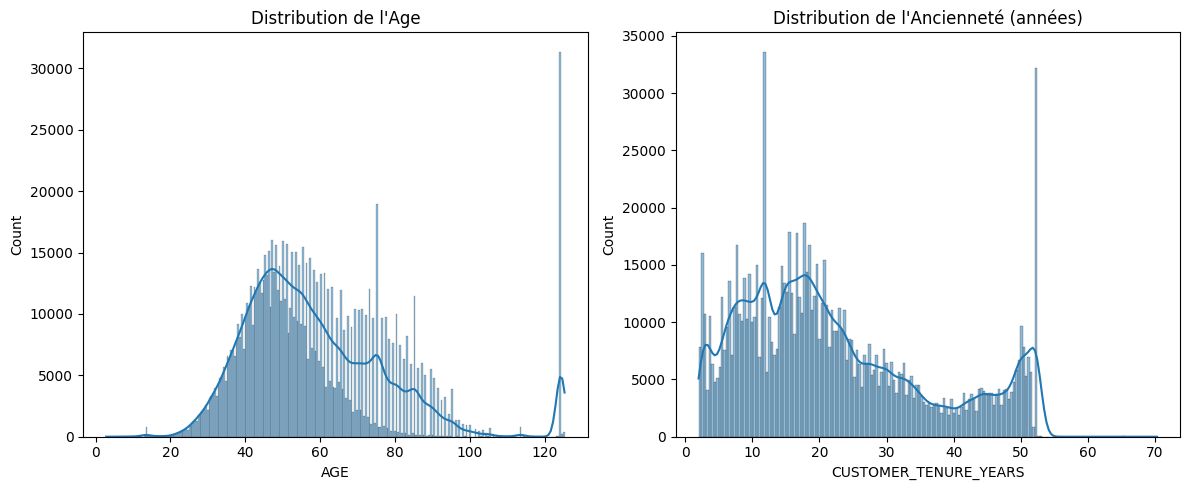

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#Histogrammes pour AGE et CUSTOMER_TENURE_YEARS. Cela montre la répartition des âges et de l'ancienneté de vos clients.
# Charger les données après feature engineering
df_final_engineered = pd.read_csv('/home/kaoutar/Desktop/data/dataset_engineered_features_for_modeling.csv')

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_final_engineered['AGE'], kde=True)
plt.title('Distribution de l\'Age')

plt.subplot(1, 2, 2)
sns.histplot(df_final_engineered['CUSTOMER_TENURE_YEARS'], kde=True)
plt.title('Distribution de l\'Ancienneté (années)')

plt.tight_layout()
plt.show()

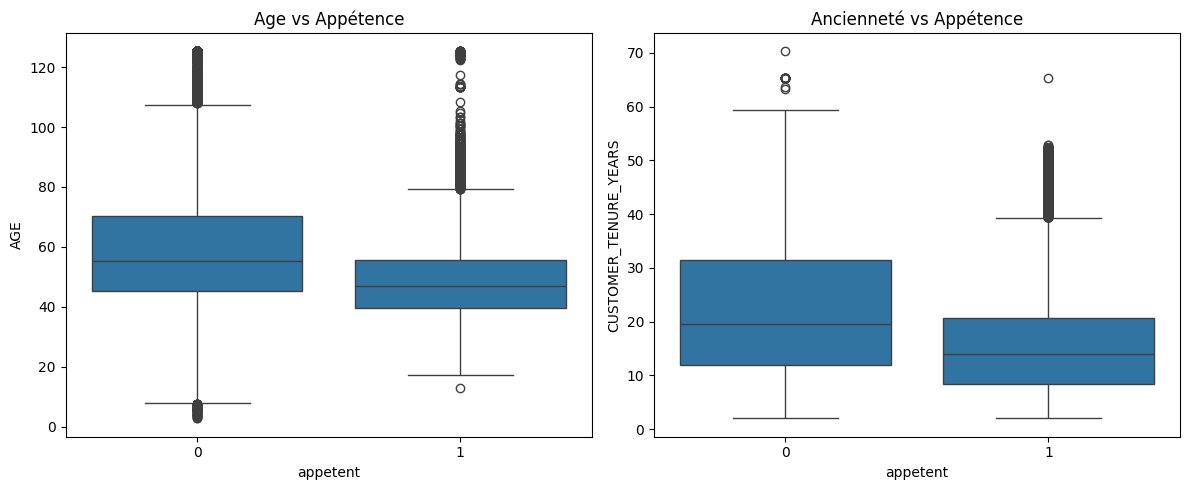

In [12]:
#Box plots (diagrammes en boîte) ou Violin plots pour AGE et CUSTOMER_TENURE_YEARS, groupés par la valeur de appetent (0 vs 1). Cela montre si l'âge moyen ou l'ancienneté diffère entre les clients appétents et non appétents.

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='appetent', y='AGE', data=df_final_engineered)
plt.title('Age vs Appétence')

plt.subplot(1, 2, 2)
sns.boxplot(x='appetent', y='CUSTOMER_TENURE_YEARS', data=df_final_engineered)
plt.title('Ancienneté vs Appétence')

plt.tight_layout()
plt.show()

Relation entre catégorielles (avant encodage) et cible (appetent) :

    Diagrammes en barres montrant le taux d'appétence (pourcentage de appetent=1) pour chaque catégorie des variables originales (GENRE, STATUT_MARITAL, CR_PROFIL, et peut-être les N catégories les plus fréquentes de RESIDENCE / CTRY_OF_BIRTH). C'est très informatif.

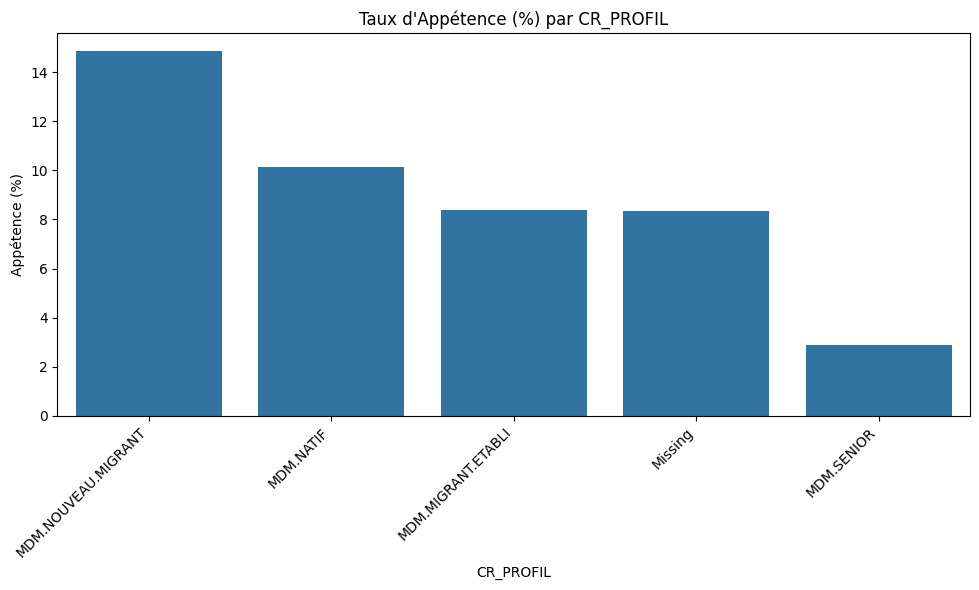

CR_PROFIL
MDM.NOUVEAU.MIGRANT    14.865941
MDM.NATIF              10.138919
MDM.MIGRANT.ETABLI      8.382469
Missing                 8.360781
MDM.SENIOR              2.887443
Name: appetent, dtype: float64


In [13]:
# Recharger les données AVANT one-hot encoding pour faciliter la visualisation des catégories
# Charger df_processed (variable intermédiaire dans le script précédent) ou recharger le CSV initial et refaire étapes avant encodage
# Supposons que df_processed contient les données après calcul age/tenure mais avant one-hot
# df_processed = pd.read_csv(...) # ou récupérer la variable si dans un notebook

# Exemple pour CR_PROFIL
if 'CR_PROFIL' in df_processed.columns and 'appetent' in df_processed.columns:
    plt.figure(figsize=(10, 6))
    # Calculer le taux moyen d'appétence par profil
    profil_appetence = df_processed.groupby('CR_PROFIL')['appetent'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=profil_appetence.index, y=profil_appetence.values)
    plt.title('Taux d\'Appétence (%) par CR_PROFIL')
    plt.ylabel('Appétence (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    print(profil_appetence) # Afficher les taux exacts

# Répéter pour GENRE, STATUT_MARITAL, etc.
# Pour RESIDENCE/CTRY_OF_BIRTH, limiter aux N catégories les plus fréquentes

Démarrage du script de Feature Engineering Avancé...
Fichier chargé avec succès: /home/kaoutar/Desktop/data/dataset_unifie_perimetre_appetent222.csv
Shape initiale: (1051281, 15)

--- Traitement des dates ---
Traitement de la colonne: DATE_OF_BIRTH
Traitement de la colonne: CUSTOMER_SINCE

--- Traitement des variables booléennes et cible ---
Distribution de la variable cible 'appetent':
appetent
0    92.3968
1     7.6032
Name: proportion, dtype: float64

--- Visualisation Taux d'Appétence par Catégorie (Target: appetent) ---


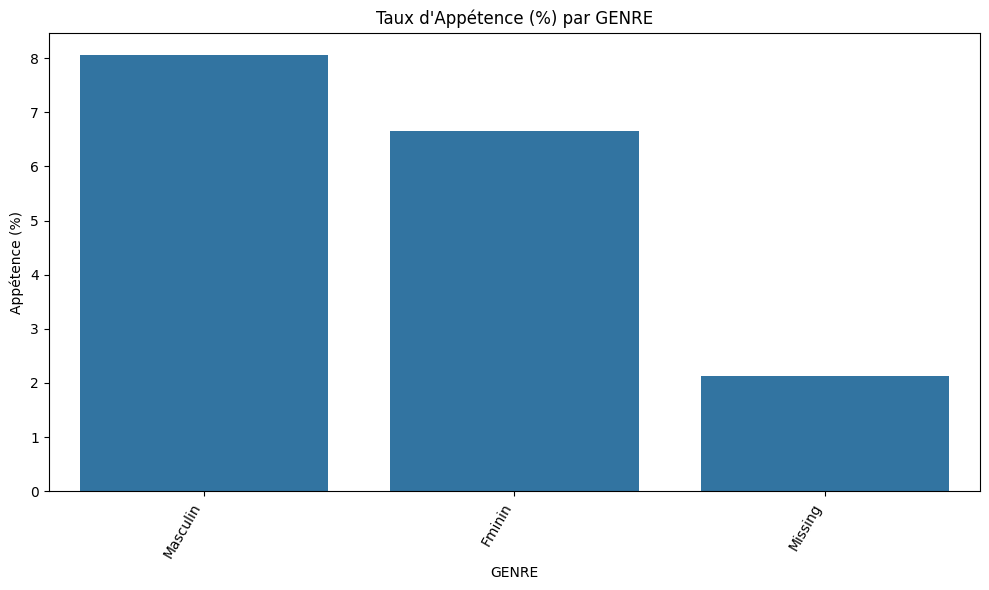

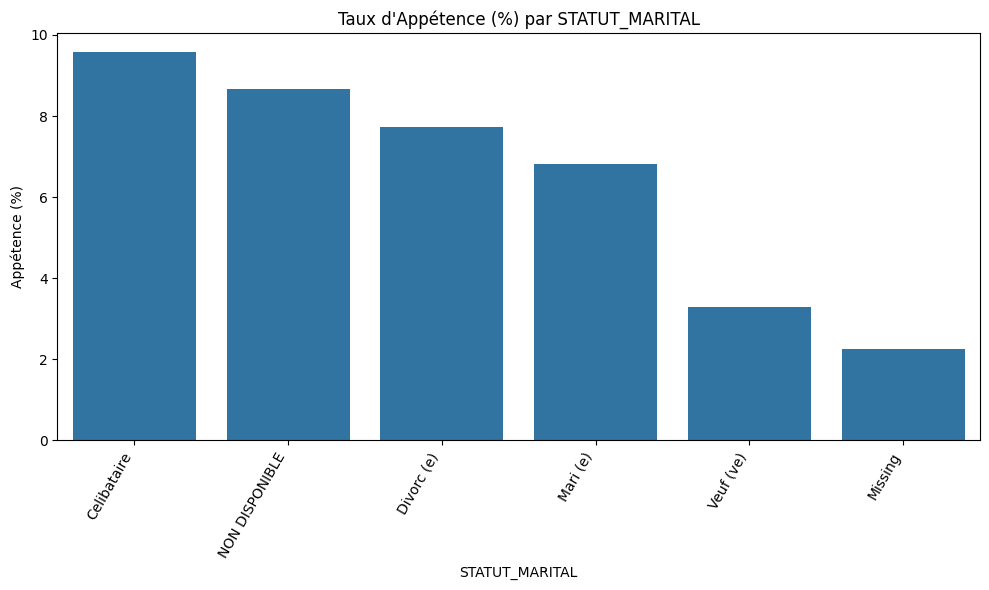

Affichage Top 15 + spécifiques pour 'CTRY_OF_BIRTH'.


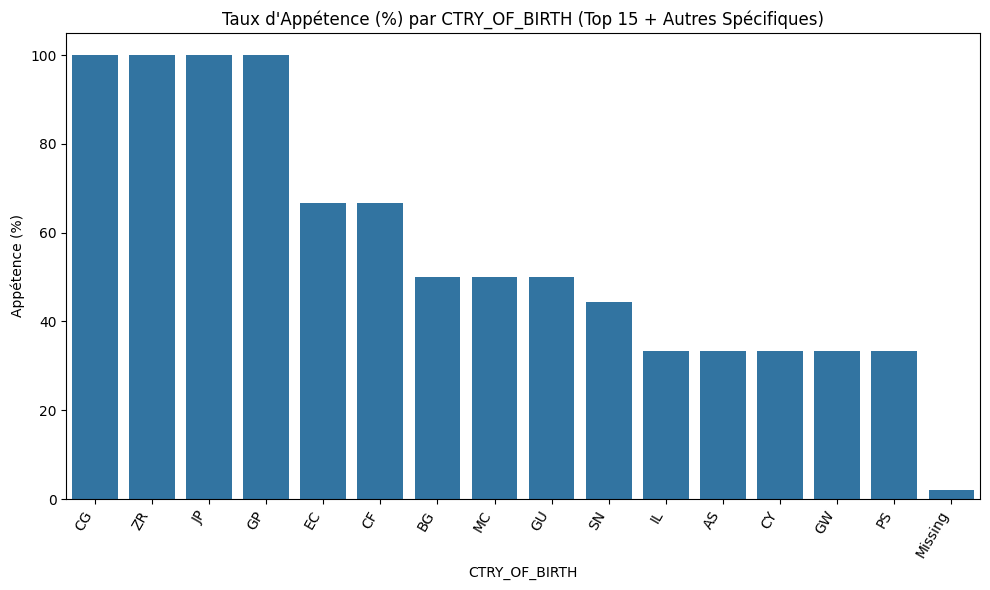

Affichage Top 15 + spécifiques pour 'RESIDENCE'.


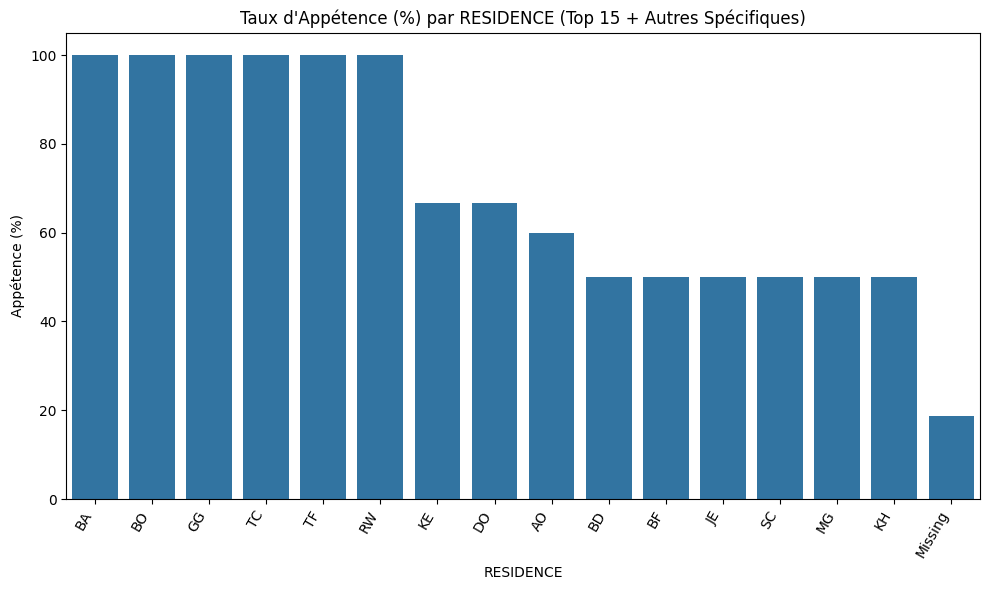

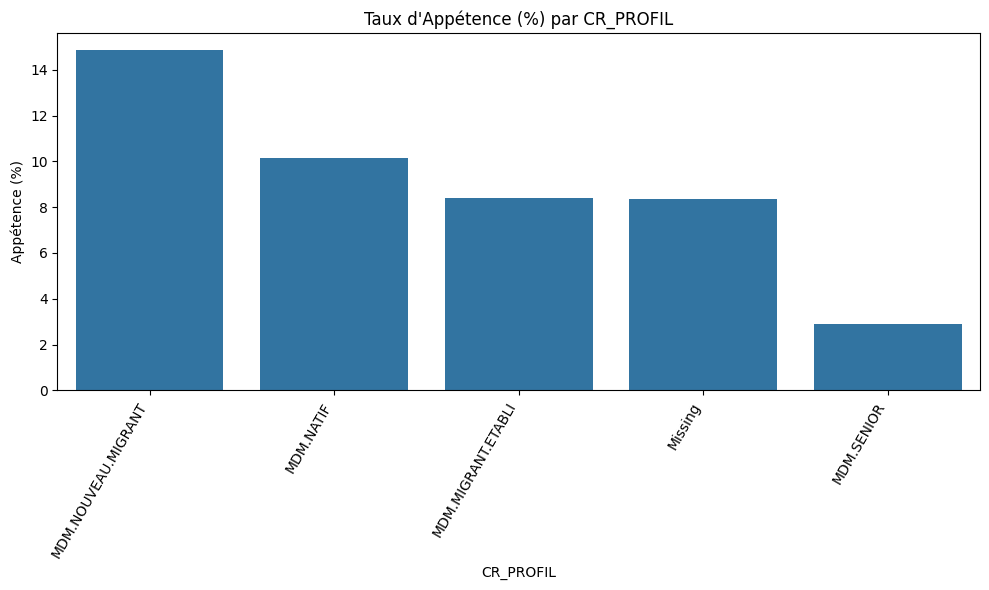


--- Traitement des variables catégorielles ---
Colonnes catégorielles identifiées: ['GENRE', 'STATUT_MARITAL', 'CTRY_OF_BIRTH', 'RESIDENCE', 'CR_PROFIL']
Regroupement des catégories apparaissant moins de 1051 fois (seuil=0.100%)
'CTRY_OF_BIRTH': 150 catégories rares regroupées en 'Other_Country'.
'RESIDENCE': 183 catégories rares regroupées en 'Other_Country'.

Application du One-Hot Encoding...
Shape après One-Hot Encoding: (1051281, 60)
Nombre de colonnes ajoutées: 43

--- Finalisation du DataFrame ---
Colonnes supprimées: ['IDENTIFIER', 'has_any_action', 'DATE_OF_BIRTH', 'CUSTOMER_SINCE']

Types de données finaux:
bool       48
int64       6
float64     2
Name: count, dtype: int64

Aucun NaN restant dans le DataFrame final.

--- Feature Engineering (avec regroupement) Terminé ---
DataFrame final shape: (1051281, 56)
Dataset avec features engineered sauvegardé dans: /home/kaoutar/Desktop/data/dataset_grouped_engineered_for_modeling.csv

Rappel: La variable cible 'appetent' est déséq

In [14]:
import pandas as pd
import numpy as np
from datetime import datetime
import os
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuration ---
DATA_PATH = "/home/kaoutar/Desktop/data"  # Adaptez si nécessaire
INPUT_FILE = os.path.join(DATA_PATH, 'dataset_unifie_perimetre_appetent222.csv')
# Nouveau nom pour le fichier de sortie final
OUTPUT_FILE = os.path.join(DATA_PATH, 'dataset_grouped_engineered_for_modeling.csv')

# Pour calculer l'âge et l'ancienneté
REFERENCE_DATE = pd.to_datetime(datetime.now())

# Seuil pour regrouper les catégories rares (ex: 0.1% des lignes)
RARE_CATEGORY_THRESHOLD_PERC = 0.001

# Nombre de Top catégories à visualiser pour les variables à haute cardinalité
TOP_N_VISUALIZE = 15
# --------------------

def load_data(file_path):
    """Charge le dataset unifié."""
    if not os.path.exists(file_path):
        print(f"Erreur: Fichier introuvable: {file_path}")
        return None
    try:
        df = pd.read_csv(file_path, sep=',')
        print(f"Fichier chargé avec succès: {file_path}")
        print(f"Shape initiale: {df.shape}")
        # print("\nAperçu initial des données:")
        # print(df.head())
        # print("\nInformations initiales sur les colonnes:")
        # df.info()
        return df
    except Exception as e:
        print(f"Erreur lors du chargement du fichier {file_path}: {e}")
        return None

def handle_dates(df):
    """Convertit les colonnes de dates, filtre les dates hors limites,
       et crée des features Age et Ancienneté."""
    print("\n--- Traitement des dates ---")
    date_cols = ['DATE_OF_BIRTH', 'CUSTOMER_SINCE']
    min_birth_date = pd.Timestamp('1900-01-01')
    max_birth_date = REFERENCE_DATE
    min_customer_date = pd.Timestamp('1950-01-01') # Ajuster si nécessaire
    max_customer_date = REFERENCE_DATE

    for col in date_cols:
        if col in df.columns:
            print(f"Traitement de la colonne: {col}")
            original_dtype = df[col].dtype
            df[col] = pd.to_datetime(df[col], errors='coerce') # Tenter la conversion standard d'abord

            # Essayer format spécifique si échec ou si on est sûr du format
            # Ex: df[col] = pd.to_datetime(df[col], errors='coerce', format='%Y%m%d')

            failed_conversions = df[col].isna().sum()
            # if failed_conversions > 0:
            #     print(f"Attention: {failed_conversions} valeurs dans '{col}' sont NaT après conversion.")

            # Filtrer les dates hors limites
            if pd.api.types.is_datetime64_any_dtype(df[col]):
                if col == 'DATE_OF_BIRTH':
                    min_valid_date, max_valid_date = min_birth_date, max_birth_date
                elif col == 'CUSTOMER_SINCE':
                    min_valid_date, max_valid_date = min_customer_date, max_customer_date
                else: # Fallback au cas où
                    min_valid_date, max_valid_date = pd.Timestamp('1678-01-01'), pd.Timestamp('2261-12-31')

                out_of_range_mask = ~df[col].isna() & ((df[col] < min_valid_date) | (df[col] > max_valid_date))
                num_out_of_range = out_of_range_mask.sum()

                if num_out_of_range > 0:
                    print(f"Attention: {num_out_of_range} dates dans '{col}' hors plage ({min_valid_date.date()} - {max_valid_date.date()}) mises à NaT.")
                    df.loc[out_of_range_mask, col] = pd.NaT
            # else:
            #     print(f"Attention: Colonne {col} non datetime après conversion.")

        else:
            print(f"Attention: Colonne '{col}' non trouvée.")

    # Création de l'âge
    if 'DATE_OF_BIRTH' in df.columns and pd.api.types.is_datetime64_any_dtype(df['DATE_OF_BIRTH']):
        delta_age = REFERENCE_DATE - df['DATE_OF_BIRTH']
        df['AGE'] = (delta_age.dt.days / 365.2425)
        df['AGE'] = df['AGE'].round(1)
        df.loc[df['AGE'] < 0, 'AGE'] = np.nan
        # print(f"Feature 'AGE' créée. NaN avant imputation: {df['AGE'].isna().sum()}")
        if df['AGE'].isna().any():
             age_median = df['AGE'].median()
             if pd.notna(age_median) and age_median > 0 and age_median < 110:
                 df['AGE'].fillna(age_median, inplace=True)
                 # print(f"NaN dans 'AGE' imputés avec la médiane: {age_median:.1f}")
             # else:
                 # print(f"Attention: Médiane AGE ({age_median}) non valide. NaN conservés.")

    # Création de l'ancienneté client
    if 'CUSTOMER_SINCE' in df.columns and pd.api.types.is_datetime64_any_dtype(df['CUSTOMER_SINCE']):
        delta_tenure = REFERENCE_DATE - df['CUSTOMER_SINCE']
        df['CUSTOMER_TENURE_YEARS'] = (delta_tenure.dt.days / 365.2425)
        df['CUSTOMER_TENURE_YEARS'] = df['CUSTOMER_TENURE_YEARS'].round(1)
        df.loc[df['CUSTOMER_TENURE_YEARS'] < 0, 'CUSTOMER_TENURE_YEARS'] = 0
        # print(f"Feature 'CUSTOMER_TENURE_YEARS' créée. NaN avant imputation: {df['CUSTOMER_TENURE_YEARS'].isna().sum()}")
        if df['CUSTOMER_TENURE_YEARS'].isna().any():
             tenure_median = df['CUSTOMER_TENURE_YEARS'].median()
             if pd.notna(tenure_median) and tenure_median >= 0:
                 df['CUSTOMER_TENURE_YEARS'].fillna(tenure_median, inplace=True)
                 # print(f"NaN dans 'CUSTOMER_TENURE_YEARS' imputés avec la médiane: {tenure_median:.1f}")
             # else:
                 # print(f"Attention: Médiane TENURE ({tenure_median}) non valide. NaN conservés.")

    return df

def handle_booleans_and_target(df):
    """Convertit les colonnes booléennes et la cible en format numérique (0/1)."""
    print("\n--- Traitement des variables booléennes et cible ---")
    bool_cols = ['connected', 'has_transaction', 'used_getchq', 'paid_vignette', 'validated_subscription', 'has_any_action', 'appetent']
    for col in bool_cols:
        if col in df.columns:
            if df[col].dtype == 'bool':
                df[col] = df[col].astype(int)
                # print(f"Colonne '{col}' convertie en entier (0/1).")
            elif df[col].dtype == 'object':
                 try: # Gérer 'True'/'False' string
                     df[col] = df[col].map({'True': 1, 'False': 0, True: 1, False: 0}).astype(int)
                     # print(f"Colonne '{col}' (object) convertie en entier (0/1).")
                 except: pass # Ignorer si la conversion échoue pour objets non booléens
            # elif pd.api.types.is_numeric_dtype(df[col]):
                 # print(f"Colonne '{col}' est déjà numérique.")
    if 'appetent' in df.columns:
        print("Distribution de la variable cible 'appetent':")
        print(df['appetent'].value_counts(normalize=True) * 100)
    return df

# --- NOUVELLE FONCTION DE VISUALISATION ---
def visualize_categorical_vs_target(df, target_col='appetent', high_card_cols=None, top_n=10):
    """Visualise le taux d'appétence moyen pour les variables catégorielles."""
    print(f"\n--- Visualisation Taux d'Appétence par Catégorie (Target: {target_col}) ---")
    if high_card_cols is None:
        high_card_cols = ['CTRY_OF_BIRTH', 'RESIDENCE'] # Colonnes à haute cardinalité par défaut

    # Identifier les colonnes catégorielles potentielles (type 'object' ou 'category')
    potential_cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    excluded_cols = ['IDENTIFIER'] # Exclure ID
    categorical_cols = [col for col in potential_cat_cols if col not in excluded_cols]

    if target_col not in df.columns:
        print(f"Erreur: Colonne cible '{target_col}' non trouvée pour la visualisation.")
        return

    for col in categorical_cols:
        if col in df.columns:
            plt.figure(figsize=(10, 6))
            
            # Calculer le taux moyen d'appétence par catégorie
            # Remplacer les NaN temporairement pour le groupby si l'imputation n'est pas encore faite
            appetence_rate = df.fillna({col: 'Missing'}) \
                              .groupby(col)[target_col].mean().mul(100) # Multiplier par 100

            # Trier et potentiellement limiter pour haute cardinalité
            appetence_rate = appetence_rate.sort_values(ascending=False)
            
            title = f'Taux d\'Appétence (%) par {col}'
            data_to_plot = appetence_rate

            if col in high_card_cols and len(appetence_rate) > top_n:
                 # Sélectionner Top N + 'Missing' (si existe) + 'Other_Country' (si existe)
                 top_categories = appetence_rate.head(top_n).index.tolist()
                 extra_cats = [cat for cat in ['Missing', 'Other_Country'] if cat in appetence_rate.index and cat not in top_categories]
                 categories_to_show = top_categories + extra_cats
                 
                 data_to_plot = appetence_rate.loc[categories_to_show]
                 title += f' (Top {top_n} + Autres Spécifiques)'
                 print(f"Affichage Top {top_n} + spécifiques pour '{col}'.")


            sns.barplot(x=data_to_plot.index, y=data_to_plot.values)
            plt.title(title)
            plt.ylabel('Appétence (%)')
            plt.xlabel(col)
            plt.xticks(rotation=60, ha='right') # Rotation augmentée pour lisibilité
            plt.tight_layout()
            plt.show()
        else:
             print(f"Colonne '{col}' non trouvée pour visualisation.")

# --- FONCTION MODIFIÉE POUR GERER LES CATEGORIES ---
def handle_categoricals(df, high_card_cols=None, threshold_perc=0.001):
    """Traite les variables catégorielles: regroupement rares, imputation, One-Hot Encoding."""
    print("\n--- Traitement des variables catégorielles ---")
    if high_card_cols is None:
        high_card_cols = ['CTRY_OF_BIRTH', 'RESIDENCE']

    potential_cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    excluded_cols = ['IDENTIFIER']
    categorical_cols = [col for col in potential_cat_cols if col not in excluded_cols]
    print(f"Colonnes catégorielles identifiées: {categorical_cols}")

    # --- Regroupement des catégories rares ---
    threshold_count = int(len(df) * threshold_perc)
    print(f"Regroupement des catégories apparaissant moins de {threshold_count} fois (seuil={threshold_perc*100:.3f}%)")
    for col in categorical_cols:
        if col in high_card_cols: # Appliquer uniquement aux colonnes à haute cardinalité
            counts = df[col].value_counts()
            rare_categories = counts[counts < threshold_count].index.tolist()
            if rare_categories:
                print(f"'{col}': {len(rare_categories)} catégories rares regroupées en 'Other_Country'.")
                df[col] = df[col].replace(rare_categories, 'Other_Country')
            # else:
            #    print(f"'{col}': Pas de catégories rares trouvées avec ce seuil.")

    # --- Imputation simple des NaN ---
    for col in categorical_cols:
        if df[col].isna().any():
            num_na = df[col].isna().sum()
            fill_value = 'Missing'
            df[col].fillna(fill_value, inplace=True)
            # print(f"NaN dans '{col}' ({num_na}) imputés avec '{fill_value}'.")

    # --- One-Hot Encoding ---
    print("\nApplication du One-Hot Encoding...")
    # Note: 'Missing' et 'Other_Country' seront encodées comme des catégories normales
    df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=False, dummy_na=False)
    print(f"Shape après One-Hot Encoding: {df_encoded.shape}")
    print(f"Nombre de colonnes ajoutées: {df_encoded.shape[1] - df.shape[1]}")
    new_cols = df_encoded.columns.difference(df.columns).tolist()
    # print(f"\nExemples de nouvelles colonnes créées: {new_cols[:5]}...")

    return df_encoded

# --- FONCTION DE FINALISATION MODIFIÉE ---
def finalize_dataframe(df):
    """Supprime les colonnes inutiles et vérifie les types."""
    print("\n--- Finalisation du DataFrame ---")
    cols_to_drop = ['IDENTIFIER', 'has_any_action'] # AJOUT de has_any_action
    original_date_cols = ['DATE_OF_BIRTH', 'CUSTOMER_SINCE']
    for col in original_date_cols:
        if col in df.columns:
            cols_to_drop.append(col)

    existing_cols_to_drop = [col for col in cols_to_drop if col in df.columns]
    if existing_cols_to_drop:
        df.drop(columns=existing_cols_to_drop, inplace=True)
        print(f"Colonnes supprimées: {existing_cols_to_drop}")

    print("\nTypes de données finaux:")
    print(df.dtypes.value_counts())
    nan_counts = df.isna().sum().sum()
    if nan_counts == 0:
         print("\nAucun NaN restant dans le DataFrame final.")
    else:
         print(f"\nAttention: {nan_counts} NaN restants !")

    return df

# --- Pipeline Principal Modifié ---
if __name__ == "__main__":
    print("Démarrage du script de Feature Engineering Avancé...")

    df_unified = load_data(INPUT_FILE)

    if df_unified is not None:
        df_processed = handle_dates(df_unified.copy()) # Utiliser une copie pour garder l'original intact si besoin
        df_processed = handle_booleans_and_target(df_processed)

        # --- APPEL DE LA VISUALISATION AVANT ENCODAGE ---
        # Visualiser sur df_processed où les catégories sont encore originales (mais NaN remplacés par 'Missing' dans la fonction)
        visualize_categorical_vs_target(df_processed.copy(), # Utiliser copie pour fillna temporaire
                                         target_col='appetent',
                                         high_card_cols=['CTRY_OF_BIRTH', 'RESIDENCE'],
                                         top_n=TOP_N_VISUALIZE)
        # ------------------------------------------------

        # Traitement catégorielles AVEC regroupement des rares
        df_encoded = handle_categoricals(df_processed,
                                          high_card_cols=['CTRY_OF_BIRTH', 'RESIDENCE'],
                                          threshold_perc=RARE_CATEGORY_THRESHOLD_PERC)

        # Finalisation AVEC suppression de 'has_any_action'
        df_final = finalize_dataframe(df_encoded)

        # Sauvegarder le DataFrame final
        try:
            df_final.to_csv(OUTPUT_FILE, index=False, sep=',')
            print(f"\n--- Feature Engineering (avec regroupement) Terminé ---")
            print(f"DataFrame final shape: {df_final.shape}") # Shape devrait être plus petite !
            print(f"Dataset avec features engineered sauvegardé dans: {OUTPUT_FILE}")

            # print("\nAperçu du DataFrame final:")
            # print(df_final.head())

            if 'appetent' in df_final.columns:
                 print("\nRappel: La variable cible 'appetent' est déséquilibrée.")
                 print("Prochaines étapes: Rééquilibrage et entraînement des modèles.")

        except Exception as e:
            print(f"\nErreur lors de la sauvegarde du fichier final: {e}")
    else:
        print("Arrêt du script car le chargement des données initiales a échoué.")

Chargement du fichier avec features grouped/engineered: /home/kaoutar/Desktop/data/dataset_grouped_engineered_for_modeling.csv
Données chargées. Shape: (1051281, 56)
Features (X) shape: (1051281, 55), Target (y) shape: (1051281,)

--- Analyse 1: Scores Statistiques Univariés ---

Scores F-value (Numérique vs Target):
AGE                      4.982601
CUSTOMER_TENURE_YEARS    4.982601
dtype: float64

Top 25 Scores Chi2 (Catégoriel/Booléen vs Target):
has_transaction                  923787.467024
connected                        327603.926777
used_getchq                       91532.110413
validated_subscription            77561.951218
paid_vignette                     75939.345052
RESIDENCE_CA                      14422.973419
CR_PROFIL_MDM.SENIOR              10482.978518
CR_PROFIL_MDM.NOUVEAU.MIGRANT     10182.299061
RESIDENCE_AE                       8408.555928
RESIDENCE_QA                       4847.187981
RESIDENCE_ES                       3429.623828
RESIDENCE_NL                 

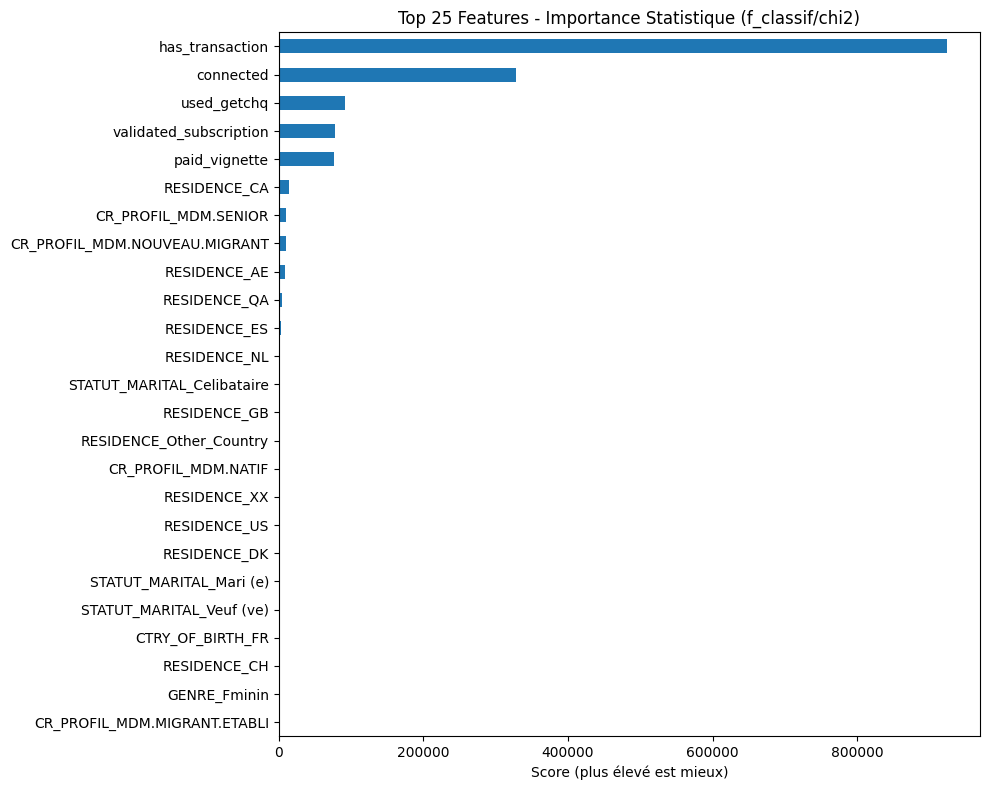


--- Analyse 2: Importance via RandomForest (class_weight='balanced') ---
Entraînement du RandomForest pour l'importance des features...
Entraînement terminé.

--- Top 25 Features (Basé sur RandomForest Importance) ---
has_transaction                  0.488546
connected                        0.265558
validated_subscription           0.153006
used_getchq                      0.041456
paid_vignette                    0.018184
CR_PROFIL_MDM.SENIOR             0.014999
CR_PROFIL_MDM.NOUVEAU.MIGRANT    0.003587
RESIDENCE_CA                     0.003480
RESIDENCE_ES                     0.002633
RESIDENCE_AE                     0.002035
CR_PROFIL_MDM.MIGRANT.ETABLI     0.000986
RESIDENCE_NL                     0.000964
STATUT_MARITAL_Celibataire       0.000545
GENRE_Masculin                   0.000538
RESIDENCE_QA                     0.000489
GENRE_Fminin                     0.000434
STATUT_MARITAL_Mari (e)          0.000331
RESIDENCE_GB                     0.000268
STATUT_MARITAL_NON DISPON

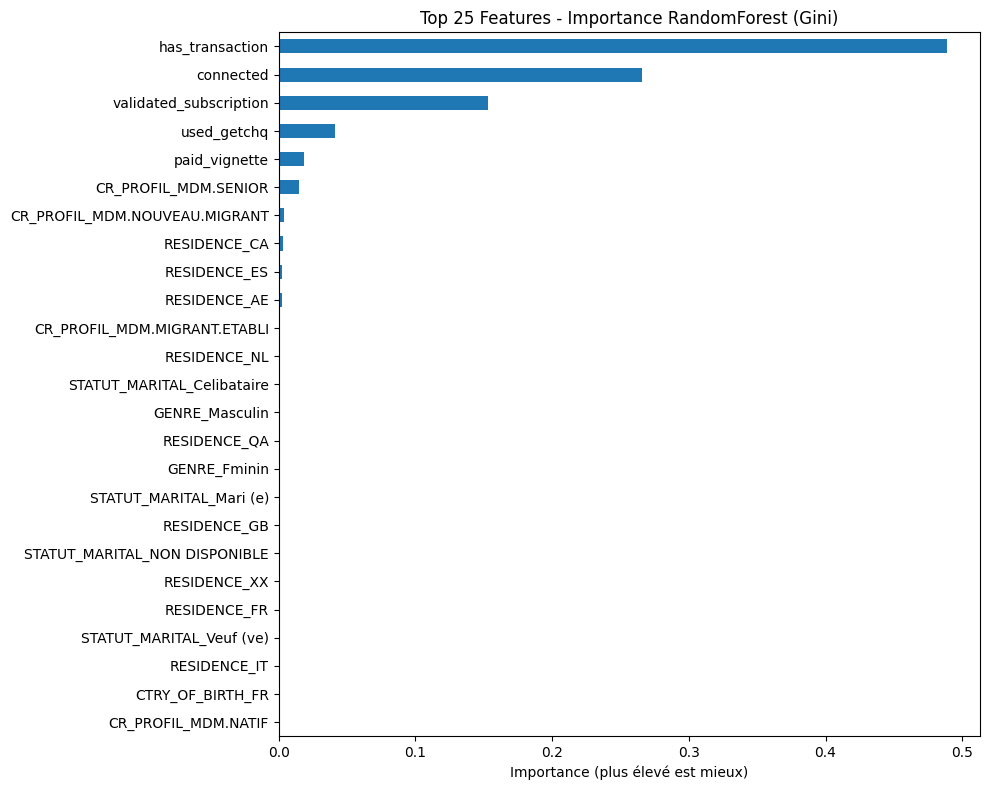

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler # Pour chi2 qui n'aime pas les négatifs (même si non présent ici)

# --- Configuration ---
DATA_PATH = "/home/kaoutar/Desktop/data"  # Adaptez si nécessaire
ENGINEERED_FILE = os.path.join(DATA_PATH, 'dataset_grouped_engineered_for_modeling.csv')
N_TOP_FEATURES = 25 # Nombre de top features à afficher
# --------------------

print(f"Chargement du fichier avec features grouped/engineered: {ENGINEERED_FILE}")

if not os.path.exists(ENGINEERED_FILE):
    print(f"Erreur: Le fichier {ENGINEERED_FILE} n'a pas été trouvé.")
else:
    try:
        df = pd.read_csv(ENGINEERED_FILE, sep=',')
        print(f"Données chargées. Shape: {df.shape}")

        # Séparer les features (X) et la cible (y)
        if 'appetent' not in df.columns:
            print("Erreur: Colonne cible 'appetent' non trouvée.")
        else:
            X = df.drop('appetent', axis=1)
            y = df['appetent']
            print(f"Features (X) shape: {X.shape}, Target (y) shape: {y.shape}")

            # Identifier les types de colonnes
            numerical_cols = ['AGE', 'CUSTOMER_TENURE_YEARS']
            # Toutes les autres sont considérées comme booléennes/catégorielles encodées (0/1)
            categorical_bool_cols = [col for col in X.columns if col not in numerical_cols]

            # --- Approche 1: Sélection Univariée Statistique ---
            print("\n--- Analyse 1: Scores Statistiques Univariés ---")

            # a) Pour les numériques (ANOVA F-value)
            if set(numerical_cols).issubset(X.columns):
                selector_num = SelectKBest(score_func=f_classif, k='all')
                selector_num.fit(X[numerical_cols], y)
                scores_num = pd.Series(selector_num.scores_, index=numerical_cols)
                print("\nScores F-value (Numérique vs Target):")
                print(scores_num.sort_values(ascending=False))
            else:
                print("Colonnes numériques non trouvées pour f_classif.")
                scores_num = pd.Series(dtype=float)


            # b) Pour les catégorielles/booléennes (Chi2)
            # Chi2 nécessite des valeurs non-négatives (nos 0/1 sont OK)
            if categorical_bool_cols:
                 # MinMaxscaler juste par sécurité si jamais une colonne bool/cat n'était pas 0/1
                 # scaler = MinMaxScaler()
                 # X_cat_scaled = scaler.fit_transform(X[categorical_bool_cols])

                 selector_cat = SelectKBest(score_func=chi2, k='all')
                 selector_cat.fit(X[categorical_bool_cols], y) # Utiliser X non scalé si sûr d'avoir 0/1
                 scores_cat = pd.Series(selector_cat.scores_, index=categorical_bool_cols)
                 print(f"\nTop {N_TOP_FEATURES} Scores Chi2 (Catégoriel/Booléen vs Target):")
                 print(scores_cat.sort_values(ascending=False).head(N_TOP_FEATURES))
            else:
                 print("Colonnes catégorielles/booléennes non trouvées pour chi2.")
                 scores_cat = pd.Series(dtype=float)


            # Combiner et afficher le Top N global (statistiques)
            all_scores_stat = pd.concat([scores_num, scores_cat]).sort_values(ascending=False)
            print(f"\n--- Top {N_TOP_FEATURES} Features (Basé sur Tests Statistiques Univariés) ---")
            print(all_scores_stat.head(N_TOP_FEATURES))

            # Visualisation des scores statistiques
            plt.figure(figsize=(10, 8))
            all_scores_stat.head(N_TOP_FEATURES).sort_values(ascending=True).plot(kind='barh')
            plt.title(f'Top {N_TOP_FEATURES} Features - Importance Statistique (f_classif/chi2)')
            plt.xlabel('Score (plus élevé est mieux)')
            plt.tight_layout()
            plt.show()


            # --- Approche 2: Importance via RandomForest ---
            print(f"\n--- Analyse 2: Importance via RandomForest (class_weight='balanced') ---")
            # Utiliser class_weight='balanced' pour atténuer l'impact de l'imbalance sur l'importance
            model_rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)

            print("Entraînement du RandomForest pour l'importance des features...")
            model_rf.fit(X, y)
            print("Entraînement terminé.")

            importances_rf = pd.Series(model_rf.feature_importances_, index=X.columns)
            top_importances_rf = importances_rf.sort_values(ascending=False)

            print(f"\n--- Top {N_TOP_FEATURES} Features (Basé sur RandomForest Importance) ---")
            print(top_importances_rf.head(N_TOP_FEATURES))

            # Visualisation de l'importance RandomForest
            plt.figure(figsize=(10, 8))
            top_importances_rf.head(N_TOP_FEATURES).sort_values(ascending=True).plot(kind='barh')
            plt.title(f'Top {N_TOP_FEATURES} Features - Importance RandomForest (Gini)')
            plt.xlabel('Importance (plus élevé est mieux)')
            plt.tight_layout()
            plt.show()

    except Exception as e:
        print(f"Une erreur est survenue: {e}")
        import traceback
        traceback.print_exc()